# Classificazione del fondo stradale con il dataset PVS

**Autori:** Dennis Brancaleoni, Anxhelo Alla

**Corso:** Machine Learning, 3° anno

## Indice

- 1. Introduzione e descrizione del dataset
- 2. Caricamento ed esplorazione dei dati
- 3. Segmentazione in finestre ed estrazione delle feature
- 4. Preprocessing: valori mancanti, standardizzazione, codifica, selezione feature
- 5. Strategia di validazione e baseline
- 6. Modelli e tuning degli iperparametri
- 7. Ensemble: Bagging e Voting
- 8. Valutazione sul test esterno
- 9. Analisi aggiuntive: posizione dei sensori, effetto della velocità
- 10. Explainability: SHAP e UMAP
- 11. Discussione e lavori futuri

In [1]:
# add the repository root to the path
# so that the src/ package can be imported without installing it.
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config

print("Project root:", config.ROOT)
print("RANDOM_STATE:", config.RANDOM_STATE)
print("Sampling rate:", config.SAMPLING_RATE_HZ, "Hz")

Project root: /Volumes/BRANCA-SSD/UNI/3ANNO/PRIMO_SEMESTRE/MACHINE_LEARNING/ml-from-scratch
RANDOM_STATE: 42
Sampling rate: 100 Hz


## 1. Introduzione e descrizione del dataset

**Dataset.** PVS – Passive Vehicular Sensors (Kaggle, "PVS - Passive Vehicular Sensors Datasets"): 9 registrazioni di guida reale, circa 3 ore in totale, ottenute con 3 veicoli × 3 scenari (percorsi). Ogni veicolo è guidato da un proprio guidatore.

| Registrazioni | Veicolo | Guidatore | Scenari (1, 2, 3) |
|---|---|---|---|
| PVS1–3 | Volkswagen Saveiro | 1 | 13,8 / 11,6 / 10,7 km |
| PVS4–6 | Fiat Bravo | 2 | 13,8 / 11,6 / 10,7 km |
| PVS7–9 | Fiat Palio | 3 | 13,8 / 11,6 / 10,7 km |

**Sensori.** Moduli MPU-9250 a 100 Hz (accelerometro in m/s², giroscopio in °/s, magnetometro in µT, temperatura del sensore in °C) su ciascun lato dell'asse anteriore: sul braccio della sospensione (*sotto* la sospensione), sulla carrozzeria sopra la ruota (*sopra* la sospensione) e sul cruscotto. Il GPS (1 Hz) fornisce la velocità in m/s.

**Target.** Tipo di fondo stradale, classificazione a 3 classi: asfalto, pavé, sterrato (`asphalt_road`, `cobblestone_road`, `dirt_road`).

**Limiti noti.** Ogni auto ha un solo guidatore (effetto auto ed effetto guidatore non separabili); le tre auto percorrono gli stessi tre percorsi; la velocità è un possibile confondente.

## 2. Caricamento ed esplorazione dei dati

In [2]:
# Setup: imports and constants. autoreload re-imports src/ every time we edit it
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (CLASS_COLORS, CLASS_ORDER, DATA_RAW, FIGURES, RECORDING_TO_CAR,
                        RECORDING_TO_SCENARIO, SAMPLING_RATE_HZ)
from src.data_loading import load_all, load_recording

pd.set_option("display.max_columns", 40)

### 2.1 Struttura dei file (PVS1)

Partiamo da una sola registrazione (PVS1) per capire cosa contengono i file: quali tabelle ci sono, a che frequenza campionano i sensori e com'è fatto il file delle etichette. 

In [3]:
# files of one recording
rec_dir = DATA_RAW / "PVS1"
for p in sorted(rec_dir.iterdir()):
    print(f"{p.name:35s} {p.stat().st_size / 1e6:8.1f} MB")

.claude-flow                             0.0 MB
dataset_gps.csv                          0.2 MB
dataset_gps_mpu_left.csv                84.5 MB
dataset_gps_mpu_right.csv               84.7 MB
dataset_labels.csv                       4.2 MB
dataset_mpu_left.csv                    75.6 MB
dataset_mpu_right.csv                   75.8 MB
dataset_settings_left.csv                0.0 MB
dataset_settings_right.csv               0.0 MB


In [4]:
# load the three tables of one recording (left side)
sensors = pd.read_csv(rec_dir / "dataset_gps_mpu_left.csv")
labels = pd.read_csv(rec_dir / "dataset_labels.csv")
gps = pd.read_csv(rec_dir / "dataset_gps.csv")

print("sensors:", sensors.shape, "| labels:", labels.shape, "| gps:", gps.shape)
display(sensors.head(3))
sensors.info()

sensors: (144036, 32) | labels: (144036, 14) | gps: (1467, 20)


,timestamp,acc_x_dashboard,acc_y_dashboard,acc_z_dashboard,acc_x_above_suspension,acc_y_above_suspension,acc_z_above_suspension,acc_x_below_suspension,acc_y_below_suspension,acc_z_below_suspension,gyro_x_dashboard,gyro_y_dashboard,gyro_z_dashboard,gyro_x_above_suspension,gyro_y_above_suspension,gyro_z_above_suspension,gyro_x_below_suspension,gyro_y_below_suspension,gyro_z_below_suspension,mag_x_dashboard,mag_y_dashboard,mag_z_dashboard,mag_x_above_suspension,mag_y_above_suspension,mag_z_above_suspension,temp_dashboard,temp_above_suspension,temp_below_suspension,timestamp_gps,latitude,longitude,speed
0,1.577219e+09,0.365116,0.167893,9.793961,0.327626,0.172733,9.781861,0.024797,0.172611,9.793824,-0.133896,-0.018883,0.138092,0.138446,0.159659,-0.072572,-0.041780,0.167302,-0.078110,22.878922,-6.040509,1.767874,75.340967,-7.537556,-0.334800,35.065355,33.340132,31.782640,1.577219e+09,-27.717841,-51.098865,0.009128
1,1.577219e+09,0.392649,0.176273,9.771216,0.381496,0.189492,9.699261,0.024797,0.194158,9.842905,-0.027084,-0.003624,0.000763,0.168963,0.068106,0.095274,0.019255,0.304631,0.150771,22.878922,-5.854647,2.089306,75.300243,-6.469241,-5.222873,34.993471,33.172402,31.782640,1.577219e+09,-27.717841,-51.098865,0.009128
2,1.577219e+09,0.409408,0.181062,9.732909,0.283333,0.182310,9.807000,0.003249,0.227677,9.888395,0.125504,-0.186729,-0.090790,-0.136213,0.159659,0.156310,-0.377473,-0.122615,0.028701,23.434686,-4.181891,0.642863,75.463140,-7.893661,-4.687194,34.993471,33.412017,31.926408,1.577219e+09,-27.717841,-51.098865,0.009128


<class 'pandas.DataFrame'>
RangeIndex: 144036 entries, 0 to 144035
Data columns (total 32 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   timestamp                144036 non-null  float64
 1   acc_x_dashboard          144036 non-null  float64
 2   acc_y_dashboard          144036 non-null  float64
 3   acc_z_dashboard          144036 non-null  float64
 4   acc_x_above_suspension   144036 non-null  float64
 5   acc_y_above_suspension   144036 non-null  float64
 6   acc_z_above_suspension   144036 non-null  float64
 7   acc_x_below_suspension   144036 non-null  float64
 8   acc_y_below_suspension   144036 non-null  float64
 9   acc_z_below_suspension   144036 non-null  float64
 10  gyro_x_dashboard         144036 non-null  float64
 11  gyro_y_dashboard         144036 non-null  float64
 12  gyro_z_dashboard         144036 non-null  float64
 13  gyro_x_above_suspension  144036 non-null  float64
 14  gyro_y_above_su

In [5]:
# Labels have no timestamp: they are aligned with the sensors by row position,
# so the two tables must have the same number of rows
assert len(sensors) == len(labels)

step = sensors["timestamp"].diff().median()      # time between two consecutive samples
duration_min = (sensors["timestamp"].iloc[-1] - sensors["timestamp"].iloc[0]) / 60
print(f"time step: {step:.3f} s | duration: {duration_min:.1f} min")

time step: 0.010 s | duration: 24.0 min


In [ ]:
# How many samples carry each label (one-hot -> one column for each category)
print(labels.sum())

# Exactly one of the three surfaces must be active on every row
surface_cols = ["asphalt_road", "cobblestone_road", "dirt_road"]
print(labels[surface_cols].sum(axis=1).value_counts())

paved_road                118168
unpaved_road               25868
dirt_road                  25868
cobblestone_road           61659
asphalt_road               56509
no_speed_bump             140581
speed_bump_asphalt           626
speed_bump_cobblestone      2829
good_road_left             56577
regular_road_left          65304
bad_road_left              22155
good_road_right            56595
regular_road_right         66038
bad_road_right             21403
dtype: int64
1    144036
Name: count, dtype: int64


In [ ]:
# Speed comes from the 1 Hz GPS and is in m/s
print(sensors["speed"].describe())
print(f"max speed: {sensors['speed'].max() * 3.6:.1f} km/h")

# GPS is 1 Hz, sensors 100 Hz: if the speed is repeated between two GPS fixes it changes
# about once every 100 samples
print("share of samples where speed changes:", (sensors["speed"].diff() != 0).mean())

count    144036.000000
mean          9.556871
std           7.746386
min           0.002526
25%           4.508887
50%           6.618945
75%          16.647470
max          26.874480
Name: speed, dtype: float64
max speed: 96.7 km/h
share of samples where speed changes: 0.009664250604015663


**Osservazioni (PVS1).**
- Il file `dataset_gps_mpu_left.csv` contiene già i segnali dei sensori a 100 Hz e la velocità GPS, quindi non serve fare noi il merge con `dataset_gps.csv`. Le colonne sono 27 segnali (accelerometro e giroscopio in 3 assi × 3 posizioni, magnetometro in 3 assi × 2 posizioni perché sotto la sospensione manca, e 3 temperature) più `timestamp`, `speed` e tre colonne GPS (`timestamp_gps`, `latitude`, `longitude`) che non useremo.
- I campioni sono 144036, a passo costante di 0,01 s (24 minuti). Le etichette non hanno timestamp: hanno lo stesso numero di righe dei sensori e le allineiamo per posizione.
- Le tre superfici sono esclusive: su ogni riga ne è attiva una sola. `paved_road` (118168) è la somma di pavé e asfalto (61659 + 56509), `unpaved_road` coincide con lo sterrato (25868). I dossi sono pochi (626 + 2829 campioni su 144036).
- La velocità è in m/s e arriva a 96,7 km/h. Cambia solo nello 0,97% dei campioni (circa 1 su 100): viene quindi ripetuta tra due misure GPS e non interpolata. La velocità media di una finestra sarà un'approssimazione a gradini.

### 2.2 Tutte le registrazioni

Carichiamo le 9 registrazioni con la stessa funzione `load_recording`, che unisce sensori, velocità, target e identificatori in una tabella con una riga per campione. Poi controlliamo che le registrazioni siano coerenti con la mappa auto/scenario della pagina Kaggle.

In [ ]:
# Load the 9 recordings (left side) into one table
df = load_all("left")
print(df.shape)
df[["recording_id", "car_id", "scenario_id", "target", "speed_mps"]].head(3)

(1080905, 35)


,recording_id,car_id,scenario_id,target,speed_mps
0,1,1,1,asphalt,0.009128
1,1,1,1,asphalt,0.009128
2,1,1,1,asphalt,0.009128


In [9]:
# One row per recording: number of samples, duration, day, car and scenario
n_samples = df.groupby("recording_id").size()
summary = pd.DataFrame({
    "n_samples": n_samples,
    "minutes": (n_samples / SAMPLING_RATE_HZ / 60).round(1),
    "date": pd.to_datetime(df.groupby("recording_id")["timestamp"].min(), unit="s").dt.date,
    "car_id": pd.Series(RECORDING_TO_CAR),
    "scenario_id": pd.Series(RECORDING_TO_SCENARIO),
})
summary

,n_samples,minutes,date,car_id,scenario_id
1,144036,24.0,2019-12-24,1,1
2,124684,20.8,2019-12-24,1,2
3,105816,17.6,2019-12-24,1,3
4,132492,22.1,2019-12-25,2,1
5,133877,22.3,2019-12-25,2,2
6,96279,16.0,2019-12-25,2,3
7,128548,21.4,2019-12-26,3,1
8,123618,20.6,2019-12-26,3,2
9,91555,15.3,2019-12-26,3,3


In [10]:
# Rows where the number of active surface labels is not 1 (ambiguous labels), per recording
for r in range(1, 10):
    lab = pd.read_csv(DATA_RAW / f"PVS{r}" / "dataset_labels.csv")
    print(f"PVS{r}:", (lab[surface_cols].sum(axis=1) != 1).sum())

PVS1: 0
PVS2: 1
PVS3: 0
PVS4: 0
PVS5: 0
PVS6: 0
PVS7: 0
PVS8: 0
PVS9: 0


**Osservazioni.**
- Tutte e 9 le registrazioni si caricano con la stessa funzione, che controlla che sensori ed etichette abbiano lo stesso numero di righe. In totale sono 1.080.905 campioni, circa 3 ore, con registrazioni da 15,3 a 24,0 minuti.
- Ogni auto è stata registrata in un solo giorno (24, 25 e 26 dicembre 2019 per le auto 1, 2 e 3), coerente con la mappa della pagina Kaggle (3 auto × 3 scenari).
- Le tre auto percorrono gli stessi tre percorsi: nella validazione (sezione 5) lasciare fuori un'auto non separa l'effetto dell'auto da quello del percorso, e un test lasciando fuori uno scenario sarà un confronto utile.
- Un solo campione su 1.080.905 ha due etichette attive: in PVS2 (riga 98890) sono attivi sia asfalto sia pavé. Lo assegniamo alla prima superficie attiva nell'ordine delle colonne (asfalto), così `target` non ha mai valori mancanti; l'effetto è trascurabile.

### 2.3 Valori mancanti e qualità dei dati

Controlliamo che nei dati non ci siano valori mancanti e ci chiediamo se i segnali sono affidabili: se i sensori saturano, se ci sono campioni a veicolo fermo (senza vibrazioni stradali) e se qualche segnale permette di riconoscere la sessione invece del fondo.

In [11]:
# Missing values in the raw PVS1 files: sensors (with GPS speed), labels and raw GPS file
print("sensors:", sensors.isna().sum().sum())
print("labels: ", labels.isna().sum().sum())
print(gps.isna().sum())      # the raw GPS file is not used in the project

sensors: 0
labels:  0
timestamp                     0
latitude                      0
longitude                     0
elevation                     0
accuracy                      0
bearing                       9
speed_meters_per_second       0
satellites                    0
provider                      0
hdop                          0
vdop                          0
pdop                          0
geoidheight                   0
ageofdgpsdata              1467
dgpsid                     1467
activity                   1467
battery                       0
annotation                 1467
distance_meters               0
elapsed_time_seconds          0
dtype: int64


In [12]:
# Missing values in the table of all recordings
print("total missing values:", df.isna().sum().sum())

total missing values: 0


In [13]:
# Accelerometer range is +-8 g = 78.4 m/s²: do the signals reach it?
acc = df.filter(like="acc_").abs()          # absolute value of the 9 accelerometer columns
print("max |acc|:", round(acc.max().max(), 1), "m/s²")
print("samples above 78 m/s²:", (acc > 78).sum().sum(), "out of", acc.size)

max |acc|: 78.9 m/s²
samples above 78 m/s²: 10 out of 9728145


In [14]:
# Samples with the vehicle (almost) stopped: no road vibration, but they still have a label
stopped = df["speed_mps"] < 0.5
print(f"share of stopped samples: {stopped.mean():.4f}")
print("share of stopped samples, per class:")
print(stopped.groupby(df["target"]).mean().round(3))

share of stopped samples: 0.0575
share of stopped samples, per class:
target
asphalt        0.127
cobblestone    0.008
dirt           0.000
Name: speed_mps, dtype: float64


In [15]:
# The sensor temperature differs between recordings: it could identify the recording
print(df.groupby("recording_id")["temp_dashboard"].mean().round(1))

recording_id
1    35.9
2    32.8
3    31.9
4    33.1
5    27.3
6    26.3
7    33.5
8    30.5
9    29.9
Name: temp_dashboard, dtype: float64


**Osservazioni.**
- **Valori mancanti.** Non ce ne sono né nei sensori né nelle etichette (PVS1 e tabella di tutte le registrazioni). Il file GPS grezzo di PVS1 ha quattro colonne completamente vuote (`ageofdgpsdata`, `dgpsid`, `activity`, `annotation`) e 9 valori mancanti in `bearing`, ma non lo usiamo: la velocità è già nel file dei sensori.
- **Fondo scala.** Il massimo dell'accelerazione è 78,9 m/s², cioè il limite del sensore (±8 g), ma solo 10 valori su 9,7 milioni superano 78 m/s²: la saturazione è trascurabile.
- **Veicolo fermo.** Il 5,75% dei campioni ha velocità < 0,5 m/s, quasi tutti sull'asfalto (12,7% dei campioni di asfalto, contro 0,8% del pavé e 0,0% dello sterrato). Da fermi non c'è vibrazione stradale, quindi questi campioni non portano informazione sul fondo: nella segmentazione si scarteranno le finestre a bassa velocità.
- **Temperatura.** La temperatura misurata è quella del sensore e cambia da una registrazione all'altra (per esempio la media di `temp_dashboard` va da 26,3 a 35,9 °C): potrebbe identificare la sessione invece del fondo.
- **Decisione.** Non useremo come feature le temperature, il magnetometro (dipende dalla direzione di marcia), le coordinate GPS (già scartate nel caricamento) né gli identificatori di registrazione, auto e scenario.

### 2.4 Classi, segnali e velocità

Guardiamo tre cose: quanto pesa ogni superficie in ogni registrazione, che aspetto ha il segnale di accelerazione nelle tre superfici e come cambia la velocità GPS tra le classi. La terza è importante perché la velocità può essere un confondente.

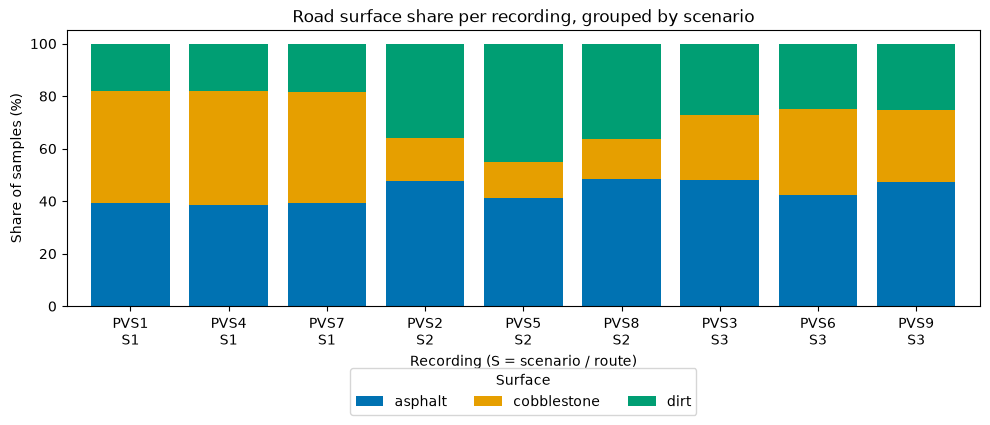

target  asphalt  cobblestone  dirt
car_id                            
1          44.5         29.0  26.5
2          40.5         29.6  29.9
3          44.7         28.6  26.7


In [16]:
# Share of each surface in every recording, recordings grouped by scenario
order = [1, 4, 7, 2, 5, 8, 3, 6, 9]
share = pd.crosstab(df["recording_id"], df["target"], normalize="index") * 100
share = share.loc[order, CLASS_ORDER]            # reorder rows (recordings) and columns (classes)

ax = share.plot(kind="bar", stacked=True, color=CLASS_COLORS, figsize=(10, 4.5), width=0.8)
ax.set_xticklabels([f"PVS{r}\nS{RECORDING_TO_SCENARIO[r]}" for r in order], rotation=0)
ax.set_xlabel("Recording (S = scenario / route)")
ax.set_ylabel("Share of samples (%)")
ax.set_title("Road surface share per recording, grouped by scenario")
ax.legend(title="Surface", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig(FIGURES / "02_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Same shares for each car
print(pd.crosstab(df["car_id"], df["target"], normalize="index").mul(100).round(1))

**Osservazioni.** La composizione delle classi dipende soprattutto dallo scenario, cioè dal percorso, che le tre auto ripetono: lo sterrato è circa il 18% in tutte e tre le registrazioni dello scenario 1 (PVS1, 4, 7), tra il 36% e il 45% nello scenario 2 e tra il 25% e il 27% nello scenario 3. Anche il pavé cambia molto con il percorso (43% nello scenario 1, 14–17% nello scenario 2). Per auto le quote sono invece simili (asfalto 40–45%, pavé circa 29%, sterrato 27–30%). Le classi non sono bilanciate: useremo la macro-F1 oltre all'accuracy e valuteremo `class_weight="balanced"`.

asphalt: mean speed 20 km/h
cobblestone: mean speed 21 km/h
dirt: mean speed 24 km/h


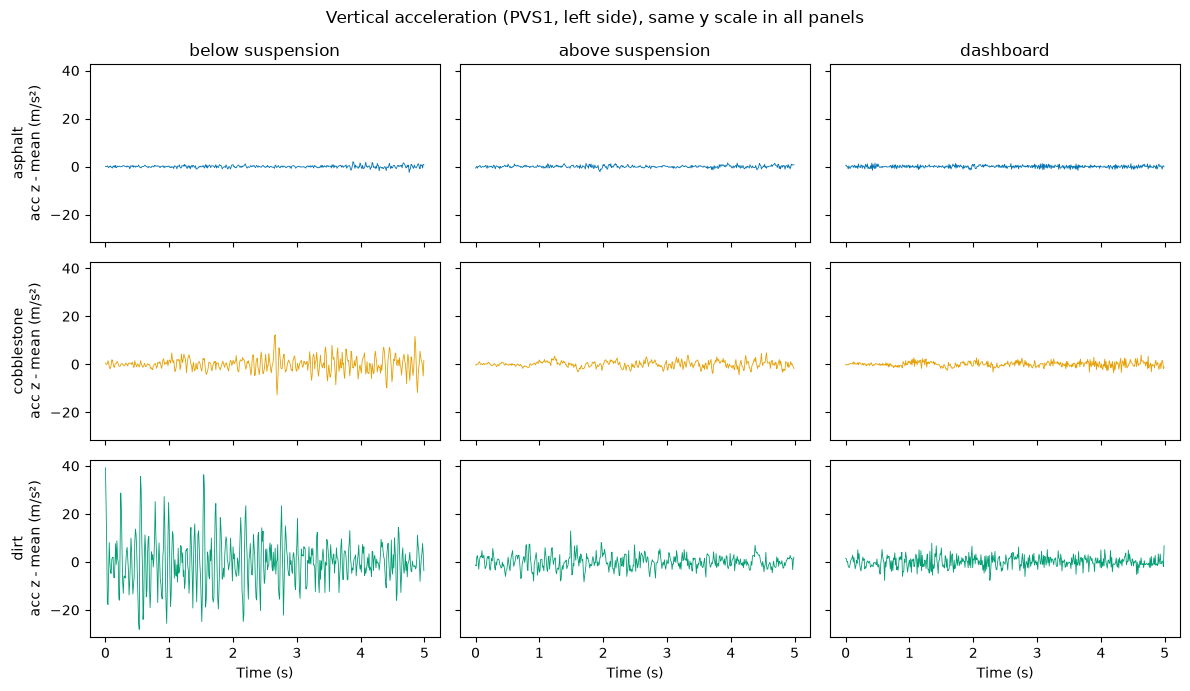

In [17]:
# 5-second excerpt of vertical acceleration for each surface in PVS1, at the three sensor positions.
# To get a clean excerpt we search 500 consecutive samples that are all of the class, with the
# vehicle moving (> 3 m/s) and no speed bump: rolling(500).sum() == 500 marks where the last
# 500 samples all satisfy the condition; idxmax() returns the first such position.
rec1 = df[df["recording_id"] == 1].reset_index(drop=True)
n = 5 * SAMPLING_RATE_HZ
positions = ["below_suspension", "above_suspension", "dashboard"]

fig, axes = plt.subplots(3, 3, figsize=(12, 7), sharex=True, sharey=True)
t = np.arange(n) / SAMPLING_RATE_HZ
for i, cls in enumerate(CLASS_ORDER):
    ok = (rec1["target"] == cls) & (rec1["speed_mps"] > 3) & ~rec1["speed_bump"]
    end = (ok.rolling(n).sum() == n).idxmax()
    segment = rec1.iloc[end - n + 1 : end + 1]
    print(f"{cls}: mean speed {segment['speed_mps'].mean() * 3.6:.0f} km/h")
    for j, pos in enumerate(positions):
        signal = segment[f"acc_z_{pos}"]
        axes[i, j].plot(t, signal - signal.mean(), lw=0.6, color=CLASS_COLORS[cls])  # remove gravity
        if i == 0:
            axes[i, j].set_title(pos.replace("_", " "))
    axes[i, 0].set_ylabel(f"{cls}\nacc z - mean (m/s²)")
for a in axes[-1]:
    a.set_xlabel("Time (s)")
fig.suptitle("Vertical acceleration (PVS1, left side), same y scale in all panels")
plt.tight_layout()
plt.savefig(FIGURES / "03_vertical_acc_by_surface.png", dpi=150, bbox_inches="tight")
plt.show()

**Osservazioni.** I tre tratti sono a velocità simile (20–24 km/h) scelti apposta, per non confondere l'effetto della superficie con quello della velocità. Sotto la sospensione l'ampiezza cresce molto con la rugosità: la deviazione standard di `acc_z` è circa 0,5 m/s² sull'asfalto, 3,0 sul pavé e 9,6 sullo sterrato. Sopra la sospensione è 0,5 / 1,3 / 2,8 e sul cruscotto 0,6 / 1,1 / 2,4. La sospensione filtra quindi le vibrazioni (circa 2 volte sul pavé e 3,4 volte sullo sterrato rispetto al punto sotto la sospensione), mentre su asfalto liscio i tre punti hanno ampiezze simili. Si tratta di un solo tratto di 5 s per classe in una sola registrazione: serve come illustrazione, non come prova. 

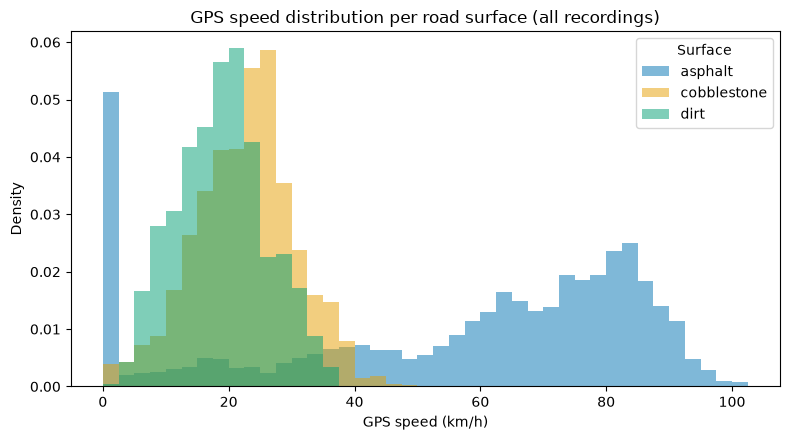

target
asphalt        65.2
cobblestone    23.3
dirt           18.9
Name: speed_mps, dtype: float64


In [18]:
# Distribution of the GPS speed for each surface (all recordings)
speed_kmh = df["speed_mps"] * 3.6

fig, ax = plt.subplots(figsize=(8, 4.5))
for cls in CLASS_ORDER:
    ax.hist(speed_kmh[df["target"] == cls], bins=np.arange(0, 105, 2.5), density=True,
            alpha=0.5, color=CLASS_COLORS[cls], label=cls)
ax.set_xlabel("GPS speed (km/h)")
ax.set_ylabel("Density")
ax.set_title("GPS speed distribution per road surface (all recordings)")
ax.legend(title="Surface")
plt.tight_layout()
plt.savefig(FIGURES / "04_speed_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

# Median speed per class in km/h
print((df.groupby("target")["speed_mps"].median() * 3.6).round(1))

**Osservazioni.** La velocità dipende molto dalla classe: la mediana è 65 km/h sull'asfalto contro 23 km/h sul pavé e 19 km/h sullo sterrato (circa 3 volte). L'asfalto ha inoltre un picco a 0 km/h (veicolo fermo). La velocità è quindi un **confondente**: un modello potrebbe imparare «veloce = asfalto» invece delle vibrazioni. La escluderemo dalle feature del modello principale e la confronteremo con e senza nella sezione 9.

### 2.5 Riepilogo delle decisioni

Decisioni prese in questa sezione, che passano alla segmentazione (sezione 3).

| Tema | Decisione |
|---|---|
| Dati | Lato sinistro, file `dataset_gps_mpu_left.csv` (il GPS è già agganciato ai sensori dagli autori) |
| Target | La superficie attiva tra asfalto, pavé e sterrato; il campione ambiguo di PVS2 prende la prima |
| Feature escluse | Coordinate GPS, temperature, magnetometro, `recording_id`, `car_id`, `scenario_id` |
| Dossi | Tenuti come flag `speed_bump` (1,6% dei campioni): da decidere nella segmentazione |
| Veicolo fermo | Proposta: scartare nella segmentazione le finestre con velocità media bassa |
| Gruppi di validazione | Auto e registrazione; limite: le 3 auto percorrono gli stessi 3 percorsi |
| Velocità | Confondente (mediana 65 km/h sull'asfalto contro 19–23): da analizzare nella sezione 9 |

## 3. Segmentazione in finestre ed estrazione delle feature

## 4. Preprocessing: valori mancanti, standardizzazione, codifica, selezione feature

## 5. Strategia di validazione e baseline

## 6. Modelli e tuning degli iperparametri

## 7. Ensemble: Bagging e Voting

## 8. Valutazione sul test esterno

## 9. Analisi aggiuntive: posizione dei sensori, effetto della velocità

## 10. Explainability: SHAP e UMAP

## 11. Discussione e lavori futuri